## Homework 6 Jiayan Wang

## Gillespie Sampling: Waiting Time and Reaction Type

For the birth–death process, the state is the current particle number $n$. The two reaction rates are

$$
a_{\mathrm{birth}}(n)=\alpha,
\qquad
a_{\mathrm{death}}(n)=n\delta.
$$

The total rate of leaving state $n$ is the sum of the reaction rates:

$$
a_0(n)=a_{\mathrm{birth}}(n)+a_{\mathrm{death}}(n)
=\alpha+n\delta.
$$

### Waiting-time distribution

Let $S(t)$ be the probability that no reaction occurs during the next time interval of length $t$. During a short interval $dt$, the probability of any reaction is approximately $a_0(n)\,dt$. Therefore,

$$
S(t+dt)=S(t)\left[1-a_0(n)\,dt\right].
$$

Taking the limit as $dt\to0$ gives

$$
\frac{dS}{dt}=-a_0(n)S.
$$

Assume $S(0)=1$, the solution is

$$
S(t)=e^{-a_0(n)t}.
$$

Thus, the waiting time $\tau$ has cumulative distribution function

$$
F(t)=P(\tau\le t)=1-e^{-a_0(n)t}.
$$


To sample a waiting time, draw a uniform random number $r_1\in(0,1)$ and set it equal to the cumulative distribution function evaluated at $\tau$:

$$
r_1=F(\tau)=1-e^{-a_0(n)\tau}.
$$

Rearrange this equation:

$$
1-r_1=e^{-a_0(n)\tau}.
$$

Take the natural logarithm of both sides:

$$
\ln(1-r_1)=-a_0(n)\tau.
$$

Solving for $\tau$ gives

$$
\boxed{
\tau=-\frac{1}{a_0(n)}\ln(1-r_1)
}.
$$

Because $1-r_1$ is also uniformly distributed on $(0,1)$, it can be renamed $r_1$. Thus, the waiting time is commonly sampled using

$$
\boxed{
\tau=\frac{1}{a_0(n)}\ln\left(\frac{1}{r_1}\right)
}.
$$

Here, $r$ is a newly sampled random number at each step. Therefore, $\tau$ is a random waiting time. Its mean is $1/a_0(n)$.



## Birth–Death Process Simulation

Let $n(t)$ denote the number of particles in the system at time $t$. The process has two possible transitions:

- **Birth:** $n \to n+1$, with rate $\alpha$.
- **Death:** $n \to n-1$, with total rate $n\delta$, where $\delta$ is the death rate per particle.

At state $n$, the total transition rate is therefore

$$
a_0(n)=\alpha+n\delta.
$$

The Gillespie algorithm simulates the process one event at a time. It first draws the waiting time to the next event from an exponential distribution with rate $a_0(n)$. It then chooses whether the event is a birth or a death, with probabilities proportional to their rates.

Each simulated trajectory is one possible realization of the stochastic process. Individual trajectories fluctuate, so we simulate many realizations and calculate their average at each time.

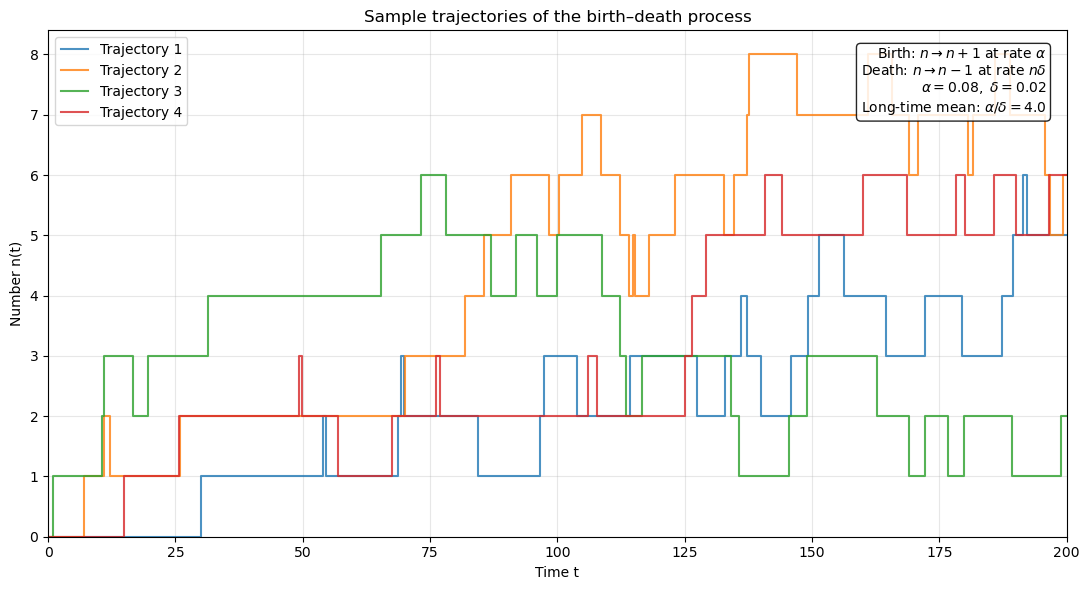

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------
# 模型参数
# --------------------
alpha = 0.08          # 出生率：n -> n + 1
delta = 0.02          # 单个个体的死亡率；状态 n 时总死亡率为 n * delta
n_initial = 0         # 初始数量
t_end = 200.0         # 延长模拟时间，以观察系统逐渐趋于稳定
n_sample_paths = 4    # 第一张图展示的随机轨迹数
n_ensemble = 2000     # 用于计算模拟平均值的轨迹总数
seed = 42

rng = np.random.default_rng(seed)


def simulate_birth_death(alpha, delta, n_initial, t_end, rng):
    """用 Gillespie 算法模拟一条出生–死亡过程。"""
    t = 0.0
    n = n_initial

    times = [t]
    states = [n]

    while t < t_end:
        # 当前状态下的出生率、死亡率和总跃迁率
        birth_rate = alpha
        death_rate = delta * n
        total_rate = birth_rate + death_rate

        # 两次跃迁之间的等待时间服从指数分布
        waiting_time = rng.exponential(scale=1.0 / total_rate)

        # 如果下一次跃迁发生在模拟终点之后，就结束
        if t + waiting_time > t_end:
            break

        t += waiting_time

        # 按出生率与总跃迁率的比例决定事件类型
        if rng.random() < birth_rate / total_rate:
            n += 1
        else:
            n -= 1

        times.append(t)
        states.append(n)

    # 补上模拟终点，便于绘制完整的阶梯轨迹
    times.append(t_end)
    states.append(n)

    return np.array(times), np.array(states)


# 生成模拟轨迹
trajectories = [
    simulate_birth_death(alpha, delta, n_initial, t_end, rng)
    for _ in range(n_ensemble)
]


# --------------------
# 图 1：展示几条随机轨迹
# --------------------
plt.figure(figsize=(11, 6))

for i, (times, states) in enumerate(trajectories[:n_sample_paths]):
    plt.step(
        times,
        states,
        where="post",
        linewidth=1.5,
        alpha=0.8,
        label=f"Trajectory {i + 1}"
    )

# 标注模型的跃迁规则和长期平均值
annotation = (
    r"Birth: $n \rightarrow n+1$ at rate $\alpha$" "\n"
    r"Death: $n \rightarrow n-1$ at rate $n\delta$" "\n"
    rf"$\alpha={alpha},\ \delta={delta}$" "\n"
    rf"Long-time mean: $\alpha/\delta={alpha / delta:.1f}$"
)

plt.text(
    0.98,
    0.97,
    annotation,
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

plt.xlabel("Time t")
plt.ylabel("Number n(t)")
plt.title("Sample trajectories of the birth–death process")
plt.xlim(0, t_end)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## Theoretical Mean

Let $P_n(t)$ be the probability that the system contains $n$ particles at time $t$. The probability evolves according to the master equation

$$
\frac{dP_n}{dt}
=
\alpha P_{n-1}
+\delta(n+1)P_{n+1}
-(\alpha+n\delta)P_n.
$$

The mean particle number is

$$
\langle n(t)\rangle
=
\sum_{n=0}^{\infty} nP_n(t).
$$

Multiplying the master equation by $n$ and summing over all states gives

$$
\frac{d\langle n\rangle}{dt}
=
\alpha-\delta\langle n\rangle.
$$

The birth process increases the mean at rate $\alpha$. The death process decreases it at rate $\delta\langle n\rangle$.

Solving this equation with the initial condition $\langle n(0)\rangle=n_0$ gives

$$
\langle n(t)\rangle
=
n_0e^{-\delta t}
+
\frac{\alpha}{\delta}\left(1-e^{-\delta t}\right).
$$

This is the theoretical mean plotted against the simulation mean. The simulation mean is calculated by averaging $n(t)$ across many independent trajectories.

As $t\to\infty$, the mean approaches the steady-state value

$$
\langle n\rangle_{\mathrm{steady}}=\frac{\alpha}{\delta}.
$$

The characteristic relaxation time is $1/\delta$.

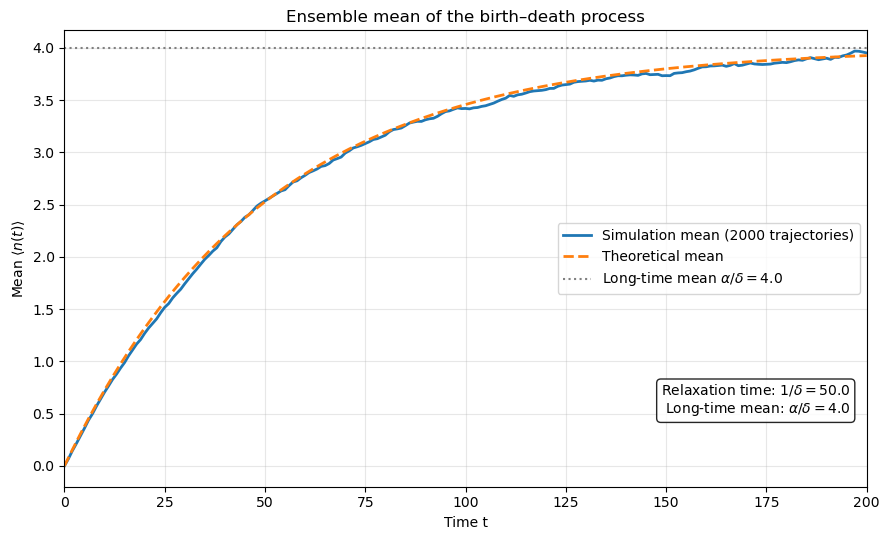

In [8]:


# --------------------
# 图 2：模拟平均值与理论平均值
# --------------------
sample_times = np.linspace(0, t_end, 201)
states_at_sample_times = np.empty((n_ensemble, len(sample_times)))

# 读取每条轨迹在各采样时刻的状态 n(t)
for i, (times, states) in enumerate(trajectories):
    indices = np.searchsorted(times, sample_times, side="right") - 1
    states_at_sample_times[i] = states[indices]

# 对所有模拟轨迹取平均
mean_simulation = states_at_sample_times.mean(axis=0)

# 理论平均值：
# <n(t)> = n_initial * exp(-delta*t)
#          + (alpha/delta) * (1 - exp(-delta*t))
mean_theory = (
    n_initial * np.exp(-delta * sample_times)
    + (alpha / delta) * (1 - np.exp(-delta * sample_times))
)

plt.figure(figsize=(9, 5.5))

plt.plot(
    sample_times,
    mean_simulation,
    label=f"Simulation mean ({n_ensemble} trajectories)",
    linewidth=2
)

plt.plot(
    sample_times,
    mean_theory,
    "--",
    label="Theoretical mean",
    linewidth=2
)

# 长时间极限：<n> = alpha / delta
plt.axhline(
    alpha / delta,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label=rf"Long-time mean $\alpha/\delta={alpha / delta:.1f}$"
)

plt.text(
    0.98,
    0.15,
    rf"Relaxation time: $1/\delta={1 / delta:.1f}$" "\n"
    rf"Long-time mean: $\alpha/\delta={alpha / delta:.1f}$",
    transform=plt.gca().transAxes,
    ha="right",
    va="bottom",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
)

plt.xlabel("Time t")
plt.ylabel(r"Mean $\langle n(t)\rangle$")
plt.title("Ensemble mean of the birth–death process")
plt.xlim(0, t_end)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()